In [1]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

zip_path = (
    "../data/raw/cmb/"
    "COM_CosmoParams_base-plikHM-TTTEEE-lowl-lowE_R3.00.zip"
)

archive = zipfile.ZipFile(zip_path)
files = archive.namelist()

target = "base_plikHM_TTTEEE_lowl_lowE"

param_files = [
    name for name in files
    if name.split("/")[-1] == target + ".paramnames"
]

assert len(param_files) == 1, param_files

param_file = param_files[0]
root = param_file[:-len(".paramnames")]

chain_files = sorted([
    name for name in files
    if name.startswith(root + "_")
    and name.endswith(".txt")
    and name[len(root) + 1:-4].isdigit()
])

assert len(chain_files) > 0

pd.DataFrame({"chain_file": chain_files})

,chain_file
0,base/plikHM_TTTEEE_lowl_lowE/base_plikHM_TTTEE...
1,base/plikHM_TTTEEE_lowl_lowE/base_plikHM_TTTEE...
2,base/plikHM_TTTEEE_lowl_lowE/base_plikHM_TTTEE...
3,base/plikHM_TTTEEE_lowl_lowE/base_plikHM_TTTEE...


In [2]:
parameter_names = []

with archive.open(param_file) as file:
    for line in file:
        text = line.decode("utf-8").strip()

        if text and not text.startswith("#"):
            parameter_names.append(text.split()[0].rstrip("*"))

BURN_IN = 0.30
properties_file = root + ".properties.ini"

if properties_file in files:
    text = archive.read(properties_file).decode("utf-8")

    for line in text.splitlines():
        if "=" in line and not line.strip().startswith("#"):
            key, value = line.split("=", 1)

            if key.strip() == "burn_removed":
                if value.strip().lower() in ["t", "true", "1"]:
                    BURN_IN = 0.0

selected = [
    "H0",
    "omegam",
    "rdrag",
    "omegabh2",
    "omegach2",
    "sigma8",
    "ns",
]

missing = [name for name in selected if name not in parameter_names]
assert not missing, missing

pd.DataFrame({
    "chains": [len(chain_files)],
    "burn_in_fraction": [BURN_IN],
})

,chains,burn_in_fraction
0,4,0.0


In [3]:
columns = ["weight", "minus_log_posterior"] + parameter_names
parts = []

for i, filename in enumerate(chain_files):
    with archive.open(filename) as file:
        chain = pd.read_csv(
            file,
            sep=r"\s+",
            comment="#",
            header=None,
            names=columns,
            usecols=["weight"] + selected,
        )

    start = int(len(chain) * BURN_IN)
    chain = chain.iloc[start:].copy()
    chain["chain"] = i + 1

    parts.append(chain)

cmb = pd.concat(parts, ignore_index=True)

assert np.isfinite(cmb.values).all()
assert (cmb["weight"] > 0).all()

cmb = cmb.rename(columns={
    "omegam": "Omega_m",
    "rdrag": "rd",
    "omegabh2": "omega_b",
    "omegach2": "omega_c",
})

cmb["H0rd"] = cmb["H0"] * cmb["rd"]

archive.close()

cmb.head()

,weight,omega_b,omega_c,ns,H0,Omega_m,sigma8,rd,chain,H0rd
0,5.0,0.022167,0.121005,0.962315,66.62354,0.324006,0.807906,147.0519,1,9797.118142
1,1.0,0.022190,0.120530,0.963581,66.80908,0.321198,0.805180,147.1527,1,9831.136507
2,5.0,0.022097,0.120462,0.961259,66.69678,0.321919,0.798361,147.2750,1,9822.768275
3,2.0,0.022121,0.120720,0.960313,66.59424,0.323548,0.799022,147.1797,1,9801.320265
4,2.0,0.022157,0.120603,0.962265,66.68701,0.322464,0.805950,147.1710,1,9814.393949


In [4]:
cmb.to_csv(
    "processed/planck_samples.csv.gz",
    index=False,
    compression="gzip",
)

pd.DataFrame({
    "dataset": ["Planck 2018 TTTEEE+lowl+lowE"],
    "model": ["base flat LCDM"],
    "source_zip": [zip_path],
    "burn_in_fraction": [BURN_IN],
    "chains": [len(chain_files)],
    "rows": [len(cmb)],
}).to_csv("processed/planck_settings.csv", index=False)

In [5]:
def weighted_quantiles(values, weights):
    order = np.argsort(values)
    values = values[order]
    weights = weights[order]

    probability = (
        np.cumsum(weights) - weights / 2
    ) / np.sum(weights)

    return np.interp([0.16, 0.50, 0.84], probability, values)


weights = cmb["weight"].values
rows = []

for name in [
    "H0", "Omega_m", "rd", "H0rd",
    "omega_b", "omega_c", "sigma8", "ns",
]:
    values = cmb[name].values
    lower, median, upper = weighted_quantiles(values, weights)

    rows.append({
        "parameter": name,
        "mean": np.average(values, weights=weights),
        "median": median,
        "lower_68": lower,
        "upper_68": upper,
        "error_minus": median - lower,
        "error_plus": upper - median,
    })

summary = pd.DataFrame(rows)
summary.to_csv("results/planck_summary.csv", index=False)

summary

,parameter,mean,median,lower_68,upper_68,error_minus,error_plus
0,H0,67.273312,67.268070,66.677250,67.873540,0.590820,0.605470
1,Omega_m,0.316551,0.316486,0.308213,0.324852,0.008273,0.008366
2,rd,147.051592,147.052400,146.756400,147.350198,0.296000,0.297798
3,H0rd,9892.785689,9891.646353,9789.214388,9996.774781,102.431964,105.128428
4,omega_b,0.022360,0.022357,0.022212,0.022509,0.000146,0.000152
5,omega_c,0.120200,0.120194,0.118846,0.121557,0.001348,0.001362
6,sigma8,0.811978,0.811849,0.804818,0.819176,0.007031,0.007327
7,ns,0.964857,0.964856,0.960546,0.969161,0.004310,0.004305


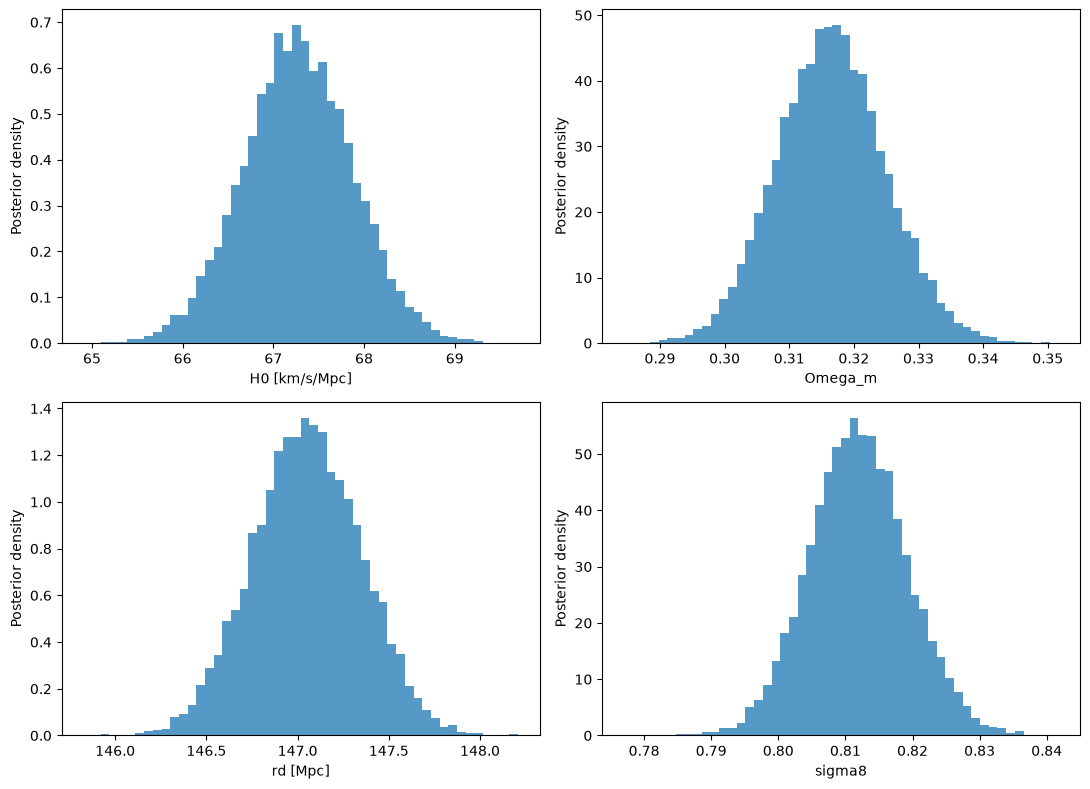

In [6]:
plt.figure(figsize=(11, 8))

parameters = ["H0", "Omega_m", "rd", "sigma8"]
labels = [
    "H0 [km/s/Mpc]",
    "Omega_m",
    "rd [Mpc]",
    "sigma8",
]

for i, (name, label) in enumerate(zip(parameters, labels)):
    plt.subplot(2, 2, i + 1)

    plt.hist(
        cmb[name],
        bins=50,
        weights=cmb["weight"],
        density=True,
        alpha=0.75,
    )

    plt.xlabel(label)
    plt.ylabel("Posterior density")

plt.tight_layout()
plt.savefig("results/planck_parameters.png", dpi=200)
plt.show()